# Supplementary studies

How much does the allocation depend on our assumptions? We keep the main notebook's method and examine one choice at a time, then test combinations of limits.

| Study | Question |
|:--|:--|
| 1. Allocation limits | How much do the weights change if we move the limits? |
| 2. Data source | How different are the Bloomberg and earlier Yahoo returns? |
| 3. Historical performance | How do the alternative allocations behave over the same period? |
| 4. Estimation window | What happens when we estimate weights using earlier data? |
| 5. Trading costs | How much do transaction costs affect the results? |
| 6. Sharpe uncertainty | How precise is the historical Sharpe estimate? |
| Appendix | Does a calculation using dollar holdings reproduce the backtest? |

The calculations use the same Bloomberg inputs as `round1_analysis.ipynb`. Tables and charts are saved in `studies/`; charts are available as PNG and PDF for the report. The main allocation is unchanged.

## Inputs and calculation functions

The current allocation uses 60 monthly returns, October 2021–September 2026. For each sensitivity test, we change the stated assumption and keep the other inputs fixed.

Portfolio volatility and each ETF's share of portfolio risk are calculated from the annual covariance matrix $\Sigma$

$$\sigma_p=\sqrt{w^\top\Sigma w}$$

$$RC_i=\frac{w_i(\Sigma w)_i}{w^\top\Sigma w}$$

The functions below apply the same long-only optimization and policy limits as the main notebook. Several starting portfolios help assess numerical stability; they do not prove a global optimum.

In [1]:
from pathlib import Path
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from IPython.display import display, Markdown

# Input paths are relative to the notebook folder.
ROOT = Path.cwd()
DATA = ROOT / "data"
RESULTS = ROOT / "results"
STUDIES = ROOT / "studies"
RESULTS.mkdir(exist_ok=True)
STUDIES.mkdir(exist_ok=True)

CAPITAL = 100_000_000
TARGET_VOLATILITY = 0.08
TRADING_COST = 0.001
ASSETS = ["SPY", "VWO", "EEMV", "DBC", "SCHD", "VGSH", "STIP"]
FIT_START = "2021-10"
FIT_END = "2026-09"
BACKTEST_START = "2016-11"
POLICY = {
    "risk_cap": 0.40,
    "capital_cap": 0.35,
    "equity_risk_cap": 0.65,
    "building_block_floor": 0.05,
    "bond_floor": 0.20,
}
GROUPS = {
    "US": ["SPY", "SCHD"],
    "EM": ["VWO", "EEMV"],
    "commodities": ["DBC"],
    "VGSH": ["VGSH"],
    "STIP": ["STIP"],
}
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

ASSET_COLORS = {"SPY": "#315b83", "VWO": "#7587aa", "EEMV": "#7caac1",
                "DBC": "#c28d48", "SCHD": "#8b7a9d", "VGSH": "#8cac98", "STIP": "#b9cedb"}

def save_chart(figure, filename):
    figure.tight_layout()
    figure.savefig(STUDIES / (filename + ".png"), dpi=180, bbox_inches="tight")
    figure.savefig(STUDIES / (filename + ".pdf"), bbox_inches="tight")
    plt.show()

STRATEGY_COLORS = {"Trained MVO": "#315b83", "Equal weight": "#bd904d",
                   "Trained risk parity": "#78a69b"}

def readable_scenario(label):
    if label == "Baseline":
        return "Baseline"
    parameter, value = label.split("=")
    names = {"risk_cap": "ETF risk cap", "building_block_floor": "All block minimums",
             "bond_floor": "Combined bond minimum", "capital_cap": "ETF weight cap",
             "equity_risk_cap": "Combined equity risk cap"}
    return f"{names.get(parameter, parameter)}: {float(value):.1%}"

In [2]:
prices = pd.read_csv(DATA / "month_end_prices.csv", index_col="month", parse_dates=True)[ASSETS]
returns = prices.pct_change(fill_method=None).iloc[1:]
training = returns.loc[FIT_START:FIT_END]
assert len(training) == 60 and np.isfinite(returns.to_numpy()).all()

annual_mean = training.mean() * 12
annual_covariance = training.cov() * 12
annual_inputs = pd.DataFrame({
    "annual_mean_input": annual_mean,
    "annual_volatility": training.std(ddof=1) * np.sqrt(12),
})

In [3]:
def portfolio_volatility(weights, covariance):
    return float(np.sqrt(weights @ covariance @ weights))


def risk_shares(weights, covariance):
    variance = weights @ covariance @ weights
    return weights * (covariance @ weights) / variance


def risk_share_gradient(weights, covariance):
    # Analytic derivatives help SLSQP handle the nonlinear risk-share limits.
    marginal_covariance = covariance @ weights
    variance = weights @ marginal_covariance
    numerator_gradient = np.diag(marginal_covariance) + np.diag(weights) @ covariance
    variance_gradient = 2 * marginal_covariance
    return (numerator_gradient / variance
            - np.outer(weights * marginal_covariance, variance_gradient) / variance**2)


def policy_margins(weights, covariance, assets, policy):
    # Nonnegative margins mean the inequalities are satisfied.
    contributions = risk_shares(weights, covariance)
    equity_mask = np.array([ticker in {"SPY", "VWO", "EEMV", "SCHD"} for ticker in assets])
    margins = {
        "long_only": float(np.min(weights)),
        "capital_cap": float(policy["capital_cap"] - np.max(weights)),
        "risk_cap": float(policy["risk_cap"] - np.max(contributions)),
        "equity_risk_cap": float(policy["equity_risk_cap"] - contributions[equity_mask].sum()),
        "bond_floor": float(sum(weights[i] for i, ticker in enumerate(assets)
                                if ticker in {"VGSH", "STIP"}) - policy["bond_floor"]),
    }
    for group, tickers in GROUPS.items():
        exposure = sum(weights[i] for i, ticker in enumerate(assets) if ticker in tickers)
        floor = policy.get("floor_" + group, policy["building_block_floor"])
        margins[group + "_floor"] = float(exposure - floor)
    return pd.Series(margins)

In [4]:
def optimize_weights(sample, policy, target=TARGET_VOLATILITY,
                     seeds=(12, 91), random_starts=100, warm_starts=()):
    assets = list(sample.columns)
    count = len(assets)
    covariance = sample.cov().to_numpy() * 12
    means = sample.mean().to_numpy() * 12
    equity_mask = np.array([ticker in {"SPY", "VWO", "EEMV", "SCHD"} for ticker in assets], dtype=float)

    constraints = [
        {"type": "eq", "fun": lambda w: w.sum() - 1,
         "jac": lambda w: np.ones(count)},
        {"type": "eq", "fun": lambda w: (w @ covariance @ w) / target**2 - 1,
         "jac": lambda w: 2 * covariance @ w / target**2},
        {"type": "ineq", "fun": lambda w: policy["risk_cap"] - risk_shares(w, covariance),
         "jac": lambda w: -risk_share_gradient(w, covariance)},
        {"type": "ineq", "fun": lambda w: policy["equity_risk_cap"] - equity_mask @ risk_shares(w, covariance),
         "jac": lambda w: -equity_mask @ risk_share_gradient(w, covariance)},
    ]
    for group, tickers in {**GROUPS, "bonds": ["VGSH", "STIP"]}.items():
        mask = np.array([ticker in tickers for ticker in assets], dtype=float)
        floor = (policy["bond_floor"] if group == "bonds"
                 else policy.get("floor_" + group, policy["building_block_floor"]))
        # Capture each group's mask and floor separately in these functions.
        constraints.append({"type": "ineq", "fun": lambda w, m=mask, f=floor: m @ w - f,
                            "jac": lambda w, m=mask: m})

    solutions = []
    diagnostics = []
    for seed in seeds:
        generator = np.random.default_rng(seed)
        starts = list(warm_starts) + list(generator.dirichlet(np.ones(count), random_starts))
        valid = []
        for initial_weights in starts:
            solution = minimize(
                fun=lambda w: -means @ w, x0=initial_weights, jac=lambda w: -means,
                bounds=[(0, policy["capital_cap"])] * count,
                constraints=constraints, method="SLSQP",
                options={"ftol": 1e-11, "maxiter": 500},
            )
            candidate = solution.x
            feasible = (abs(candidate.sum() - 1) < 1e-7
                        and abs(portfolio_volatility(candidate, covariance) - target) < 1e-7
                        and policy_margins(candidate, covariance, assets, policy).min() >= -1e-7)
            if solution.success and feasible:
                valid.append(solution)
        diagnostics.append({"seed": seed, "starts": len(starts), "verified_solutions": len(valid),
                            "best_mean_return": -min(s.fun for s in valid) if valid else np.nan})
        solutions.extend(valid)
    if not solutions:
        raise RuntimeError("No verified feasible allocation found; do not substitute arbitrary weights.")
    best = min(solutions, key=lambda solution: solution.fun)
    return best.x, pd.DataFrame(diagnostics)

## 1. How much do the weights depend on the limits?

We keep the ETF universe, 60-month input window, return objective and 8% volatility target fixed. The baseline is the policy used in the main notebook.

| Limit | Baseline |
|:--|--:|
| Maximum risk share per ETF | 40% |
| Maximum capital weight per ETF | 35% |
| Maximum combined equity risk share | 65% |
| Minimum capital in each building block | 5% |
| Minimum combined VGSH and STIP capital | 20% |

**Step 1:** Solve the baseline and define nearby limits. **Step 2:** Re-optimize all weights for each specification. **Step 3:** Compare the resulting weights with the baseline.

The 108 specifications consist of one baseline, 17 changes to common limits, ten changes to individual minimums and 80 combinations. Each sensitivity optimization uses 48 starting portfolios across two seeds. Weight comparisons use the exact optimizer solution before rounding.

The fraction of capital that moves between ETFs is

$$\text{capital reassigned}=\frac12\sum_i\left|w_i-w_i^{baseline}\right|$$

Moving 2% of capital from one ETF to another counts as 2% reassigned. We also record the largest change in any single ETF's weight.

In [5]:
baseline_weights, baseline_diagnostics = optimize_weights(training, POLICY)
specifications = [("Baseline", "baseline", POLICY.copy())]
def add_specification(label, kind, **changes):
    specifications.append((label, kind, POLICY | changes))

variations = {
    "risk_cap": [0.35, 0.375, 0.425, 0.45],
    "building_block_floor": [0.025, 0.075],
    "bond_floor": [0.15, 0.25, 0.30],
    "capital_cap": [0.30, 0.325, 0.375, 0.40],
    "equity_risk_cap": [0.55, 0.60, 0.70, 0.75],
}
for parameter, limits in variations.items():
    for limit in limits:
        add_specification(f"{parameter}={limit:.3f}", "one_limit", **{parameter: limit})
for group in GROUPS:
    for limit in [0.025, 0.075]:
        add_specification(f"{group} minimum={limit:.3f}", "individual_floor", **{"floor_" + group: limit})
for risk_cap, floor, capital_cap, equity_cap in product(
    [0.35, 0.40, 0.45], [0.025, 0.05, 0.075], [0.30, 0.35, 0.40], [0.60, 0.65, 0.70]
):
    candidate_policy = POLICY | {"risk_cap": risk_cap, "building_block_floor": floor,
                                "capital_cap": capital_cap, "equity_risk_cap": equity_cap}
    if candidate_policy != POLICY:
        specifications.append((f"Joint {len(specifications)}", "joint", candidate_policy))
assert len(specifications) == 108

### Baseline reference

These are the rounded target weights used in the main notebook. The sensitivity tests below compare exact solutions so that rounding does not affect the comparison.

In [6]:
exact_weights, solver_diagnostics = baseline_weights, baseline_diagnostics
covariance = annual_covariance.to_numpy()

def acceptable_rounding(weights):
    volatility = portfolio_volatility(weights, covariance)
    return (abs(weights.sum() - 1) < 1e-12
            and 0.07 <= volatility <= TARGET_VOLATILITY + 1e-10
            and policy_margins(weights, covariance, ASSETS, POLICY).min() >= -1e-10)

target_weights = np.round(exact_weights, 4)
target_weights[-1] = 1 - target_weights[:-1].sum()
if not acceptable_rounding(target_weights):
    # Try adjacent 0.01 percentage-point grid values, not a new portfolio search.
    lower_weights = np.floor(exact_weights * 10_000) / 10_000
    feasible_roundings = []
    for increments in product([0, 1], repeat=len(ASSETS)):
        candidate = lower_weights + np.array(increments) / 10_000
        if acceptable_rounding(candidate):
            feasible_roundings.append(candidate)
    if not feasible_roundings:
        raise RuntimeError("No nearby rounded allocation satisfies the policy limits.")
    target_weights = min(feasible_roundings, key=lambda w: np.sum((w - exact_weights)**2))

allocation = pd.DataFrame({
    "exact_weight": exact_weights,
    "target_weight": target_weights,
    "risk_share": risk_shares(target_weights, covariance),
    "target_value_usd": target_weights * CAPITAL,
}, index=ASSETS)
allocation.index.name = "ticker"

display(allocation.loc[allocation["target_weight"] > 1e-8, ["target_weight", "risk_share"]]
        .rename(columns={"target_weight": "Main target weight", "risk_share": "Risk share"})
        .style.format("{:.2%}"))

,Main target weight,Risk share
ticker,,
SPY,26.08%,40.00%
EEMV,9.66%,8.62%
DBC,26.95%,39.99%
SCHD,3.28%,4.79%
VGSH,5.00%,0.37%
STIP,29.03%,6.23%


In [7]:
covariance = annual_covariance.to_numpy()
sensitivity_rows = []
sensitivity_weights = {}
for number, (label, kind, policy) in enumerate(specifications):
    weights, diagnostics = optimize_weights(
        training, policy, seeds=(17, 83), random_starts=22,
        warm_starts=(baseline_weights, np.ones(len(ASSETS)) / len(ASSETS)),
    )
    direct_returns = training.to_numpy() @ weights
    direct_variance = np.var(direct_returns, ddof=1) * 12
    direct_risk = np.array([
        weights[i] * np.cov(training.iloc[:, i], direct_returns, ddof=1)[0, 1] * 12 / direct_variance
        for i in range(len(ASSETS))
    ])
    assert np.max(abs(direct_risk - risk_shares(weights, covariance))) < 1e-10
    assert abs(np.sqrt(direct_variance) - TARGET_VOLATILITY) < 1e-7
    assert policy_margins(weights, covariance, ASSETS, policy).min() >= -1e-7
    seed_gap = diagnostics["best_mean_return"].max() - diagnostics["best_mean_return"].min()
    assert diagnostics["best_mean_return"].notna().all() and seed_gap < 1e-9
    row = {"scenario": label, "kind": kind, **policy,
           **dict(zip(ASSETS, weights)),
           "max_weight_change_pp": float(np.max(abs(weights - baseline_weights)) * 100),
           "capital_reassigned_pct": float(np.abs(weights - baseline_weights).sum() / 2 * 100),
           "estimated_mean": float(annual_mean.to_numpy() @ weights),
           "estimated_volatility": float(np.sqrt(direct_variance)),
           "seed_objective_gap": float(seed_gap),
           "verified_solutions": int(diagnostics["verified_solutions"].sum())}
    row.update({ticker + "_risk": float(direct_risk[i]) for i, ticker in enumerate(ASSETS)})
    sensitivity_rows.append(row)
    sensitivity_weights[label] = weights
sensitivity = pd.DataFrame(sensitivity_rows).set_index("scenario")
sensitivity.to_csv(STUDIES / "constraint_sensitivity.csv")

individual_changes = sensitivity.loc[sensitivity["kind"] != "joint", ASSETS + ["capital_reassigned_pct"]]
display(individual_changes.rename(index=readable_scenario, columns={"capital_reassigned_pct": "Capital moved (%)"})
        .style.format({**{a: "{:.2%}" for a in ASSETS}, "Capital moved (%)": "{:.2f}"}))

,SPY,VWO,EEMV,DBC,SCHD,VGSH,STIP,Capital moved (%)
scenario,,,,,,,,
Baseline,26.08%,0.00%,9.65%,26.96%,3.28%,5.00%,29.03%,0.00
ETF risk cap: 35.0%,22.57%,0.00%,12.17%,24.56%,7.87%,5.00%,27.84%,7.10
ETF risk cap: 37.5%,24.30%,0.00%,10.95%,25.77%,5.61%,5.00%,28.36%,3.64
ETF risk cap: 42.5%,27.92%,0.00%,8.27%,28.13%,0.83%,5.00%,29.85%,3.83
ETF risk cap: 45.0%,29.83%,0.00%,5.00%,29.19%,0.00%,10.77%,25.20%,11.76
All block minimums: 2.5%,26.10%,0.00%,9.60%,26.93%,3.03%,2.50%,31.84%,2.82
All block minimums: 7.5%,26.07%,0.00%,9.70%,26.98%,3.52%,7.50%,26.22%,2.82
Combined bond minimum: 15.0%,26.08%,0.00%,9.65%,26.96%,3.28%,5.00%,29.03%,0.00
Combined bond minimum: 25.0%,26.08%,0.00%,9.65%,26.96%,3.28%,5.00%,29.03%,0.00


### Changing the risk cap

Each column below is a newly optimized portfolio. The colours show capital weights; the horizontal labels show the maximum permitted risk share per ETF.

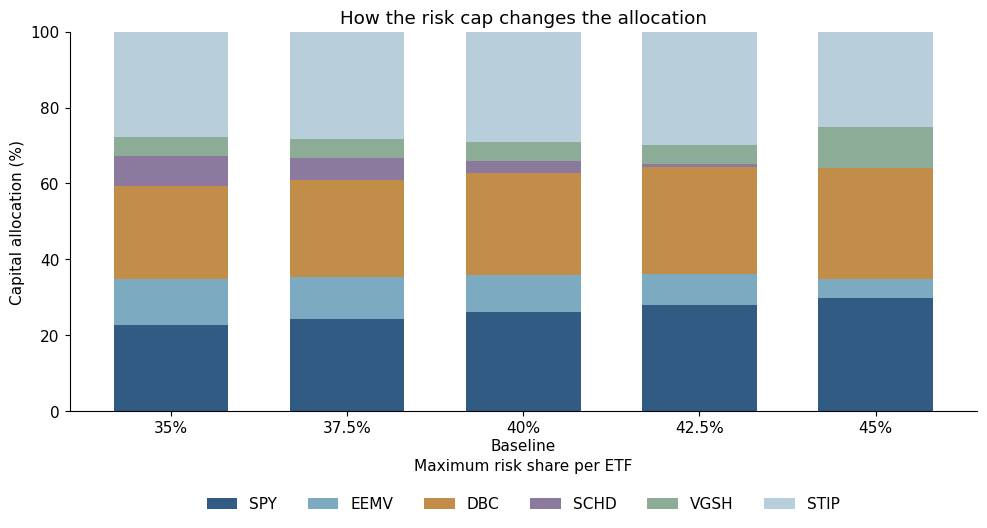

In [8]:
selected = ["risk_cap=0.350", "risk_cap=0.375", "Baseline", "risk_cap=0.425", "risk_cap=0.450"]
visible_assets = [ticker for ticker in ["SPY", "VWO", "EEMV", "DBC", "SCHD", "VGSH", "STIP"]
                  if sensitivity.loc[selected, ticker].max() > 1e-8]
chart = sensitivity.loc[selected, visible_assets].copy()
chart.index = ["35%", "37.5%", "40%\nBaseline", "42.5%", "45%"]
figure, axis = plt.subplots(figsize=(10, 5.5))
(chart * 100).plot.bar(stacked=True, ax=axis, width=0.65, rot=0,
                      color=[ASSET_COLORS[ticker] for ticker in visible_assets])
axis.set(title="How the risk cap changes the allocation", ylim=(0, 100),
         xlabel="Maximum risk share per ETF", ylabel="Capital allocation (%)")
axis.legend(ncol=len(visible_assets), frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.19))
save_chart(figure, "risk_cap_allocations")

### Which individual limits make a difference?

This chart shows changes that move more than 0.01% of capital after changing one limit. The full table above includes the changes that have little or no effect.

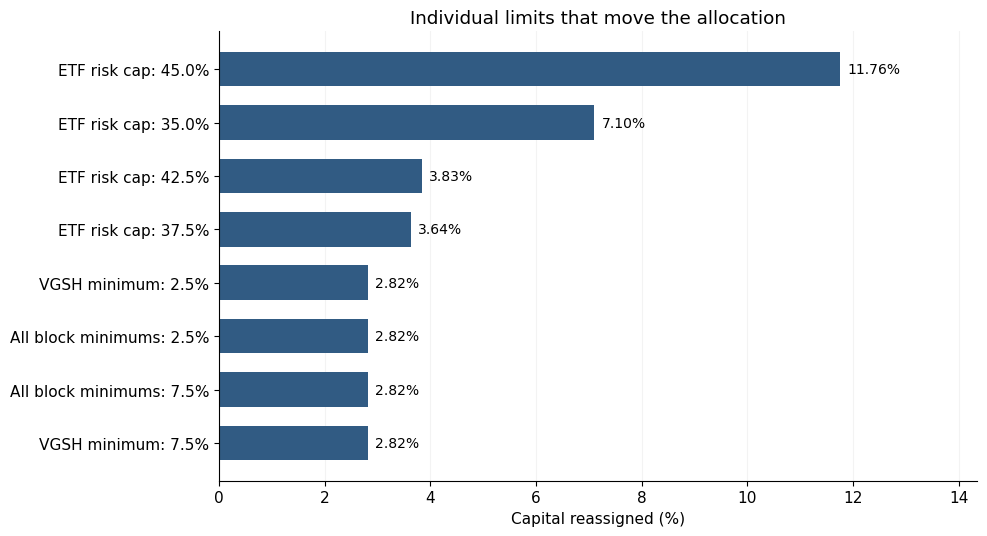

In [9]:
single_changes = sensitivity.loc[sensitivity["kind"].isin(["one_limit", "individual_floor"])]
largest_single_changes = single_changes.loc[single_changes["capital_reassigned_pct"] > 0.01].sort_values("capital_reassigned_pct")
figure, axis = plt.subplots(figsize=(10, 5.5))
bars = axis.barh([readable_scenario(label) for label in largest_single_changes.index],
                 largest_single_changes["capital_reassigned_pct"], color="#315b83", height=0.65)
axis.bar_label(bars, fmt="%.2f%%", padding=5, fontsize=10)
axis.set(title="Individual limits that move the allocation", xlabel="Capital reassigned (%)")
axis.set_xlim(0, largest_single_changes["capital_reassigned_pct"].max() * 1.22)
axis.grid(axis="x", alpha=0.15)
axis.set_axisbelow(True)
save_chart(figure, "individual_limit_sensitivity")

In [10]:
nearby = sensitivity.loc[["risk_cap=0.375", "risk_cap=0.425"], "capital_reassigned_pct"]
largest_joint = sensitivity.loc[sensitivity["kind"] == "joint", "capital_reassigned_pct"].max()
display(Markdown(
    f"Moving the risk cap from **40% to 37.5%** reassigns **{nearby.iloc[0]:.2f}%** of capital; "
    f"moving it to **42.5%** reassigns **{nearby.iloc[1]:.2f}%**. "
    f"The largest tested change to several limits together reassigns **{largest_joint:.2f}%**.\n\n"
    "The risk cap and VGSH minimum affect the allocation. Several other limits do not bind at the baseline. "
    "These are policy choices: the sensitivity test describes their consequences rather than identifying one uniquely correct threshold."
))

Moving the risk cap from **40% to 37.5%** reassigns **3.64%** of capital; moving it to **42.5%** reassigns **3.83%**. The largest tested change to several limits together reassigns **24.49%**.

The risk cap and VGSH minimum affect the allocation. Several other limits do not bind at the baseline. These are policy choices: the sensitivity test describes their consequences rather than identifying one uniquely correct threshold.

## 2. How different are the two data sources?

We compare monthly returns from the earlier Yahoo dataset with Bloomberg over their common months. Bloomberg remains the input to the portfolio calculations.

For each ETF and month, the absolute difference is

$$d_{i,t}=\left|r_{i,t}^{Bloomberg}-r_{i,t}^{Yahoo}\right|$$

The table reports the average difference and the largest monthly difference. The chart expresses them in basis points: one basis point is 0.01 percentage points of return.

The saved Bloomberg request confirms dividend and split adjustments for SPY. The other ETF columns were supplied as values without their original request settings; their returns are treated as total-return proxies. Agreement between sources does not establish that all request settings were identical.

In [11]:
yahoo_prices = pd.read_csv(DATA / "yahoo_month_end_prices.csv", index_col=0, parse_dates=True)[ASSETS]
yahoo_returns = yahoo_prices.pct_change(fill_method=None).iloc[1:]
common_months = returns.index.intersection(yahoo_returns.index)
absolute_difference = (returns.loc[common_months] - yahoo_returns.loc[common_months]).abs()
source_comparison = pd.DataFrame({
    "mean_absolute_return_difference": absolute_difference.mean(),
    "max_absolute_return_difference": absolute_difference.max(),
    "largest_difference_month": absolute_difference.idxmax(),
})
source_comparison.to_csv(STUDIES / "source_comparison.csv")

display(source_comparison.rename(columns={
    "mean_absolute_return_difference": "Mean absolute difference",
    "max_absolute_return_difference": "Largest absolute difference",
    "largest_difference_month": "Month of largest difference"})
    .style.format({"Mean absolute difference": "{:.5%}", "Largest absolute difference": "{:.5%}",
                   "Month of largest difference": lambda value: value.strftime("%b %Y")}))

,Mean absolute difference,Largest absolute difference,Month of largest difference
SPY,0.00020%,0.00408%,Jun 2012
VWO,0.00124%,0.02543%,Oct 2013
EEMV,0.00035%,0.00894%,Jul 2022
DBC,0.00025%,0.00345%,Dec 2018
SCHD,0.00076%,0.01451%,Nov 2012
VGSH,0.00162%,0.05462%,Nov 2015
STIP,0.00164%,0.19009%,Nov 2012


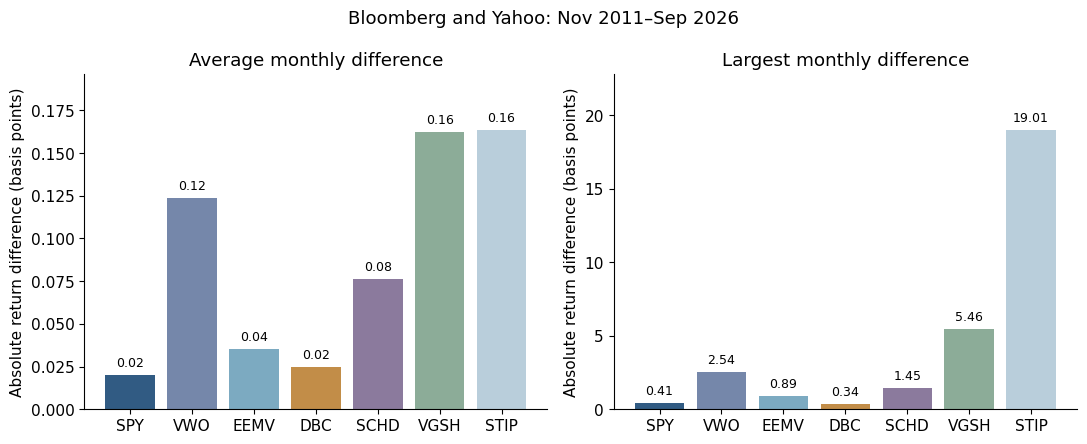

In [12]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for axis, (column, title) in zip(axes, [
    ("mean_absolute_return_difference", "Average monthly difference"),
    ("max_absolute_return_difference", "Largest monthly difference"),
]):
    bars = axis.bar(source_comparison.index, source_comparison[column] * 10_000,
                    color=[ASSET_COLORS[ticker] for ticker in source_comparison.index])
    axis.bar_label(bars, fmt="%.2f", padding=4, fontsize=9)
    axis.set(title=title, ylabel="Absolute return difference (basis points)")
    axis.set_ylim(0, source_comparison[column].max() * 10_000 * 1.2)
figure.suptitle(f"Bloomberg and Yahoo: {common_months[0]:%b %Y}–{common_months[-1]:%b %Y}", fontsize=13)
save_chart(figure, "data_source_differences")

## 3. How do the alternative limits affect historical performance?

Each allocation keeps its own target weights fixed over November 2016–September 2026, with monthly rebalancing. All cases use the same returns, risk-free proxy and cost of 10 basis points per dollar bought or sold, including the initial investment.

### Monthly calculation

We first measure the trades needed to restore the target weights after the previous month's drift. Both purchases and sales enter the traded fraction $T_t$

$$T_t=\sum_i\left|w_i-\widetilde{w}_{i,t}\right|$$

$$r_{p,t}^{net}=(1-cT_t)(1+w^\top r_t)-1$$

Here $c$ is the cost per dollar traded. The risk-free proxy uses the last DGS1MO yield available before the month starts, accrued over that month's calendar days

$$r_{f,t}=\frac{y_{t^-}}{100}\frac{D_t}{365}$$

$$\widehat{S}=\frac{12\operatorname{mean}(r_p^{net}-r_f)}{\sqrt{12}\operatorname{sd}(r_p^{net})}$$

These are retrospective comparisons: the weights use the current estimation window and the limits were considered after reviewing history. We use the results to describe sensitivity, rather than select the limits with the highest historical Sharpe. Exact weights are used here, so the baseline differs slightly from the rounded allocation in the main notebook.

In [13]:
treasury = pd.read_csv(DATA / "fred_dgs1mo.csv", parse_dates=["observation_date"])
treasury["DGS1MO"] = pd.to_numeric(treasury["DGS1MO"], errors="coerce")
treasury = treasury.dropna(subset=["DGS1MO"]).set_index("observation_date").sort_index()
risk_free_rows = []
for month in returns.index:
    first_day = month.replace(day=1)
    prior = treasury.loc[treasury.index < first_day, "DGS1MO"]
    if prior.empty:
        raise ValueError(f"No Treasury yield available before {first_day.date()}.")
    annual_yield_percent = float(prior.iloc[-1])
    monthly_proxy = annual_yield_percent / 100 * month.days_in_month / 365
    risk_free_rows.append([month, prior.index[-1], annual_yield_percent, monthly_proxy])
risk_free_table = pd.DataFrame(risk_free_rows, columns=[
    "month", "yield_observation_date", "annual_yield_percent", "monthly_rf_proxy"
]).set_index("month")
risk_free = risk_free_table["monthly_rf_proxy"]

In [14]:
def simulate_fixed_weights(weights, asset_returns, trading_cost=TRADING_COST):
    drifted_weights = np.zeros(len(weights))
    rows = []
    for month, observations in asset_returns.iterrows():
        traded_fraction = float(np.abs(weights - drifted_weights).sum())
        gross_return = float(weights @ observations.to_numpy())
        net_return = (1 - trading_cost * traded_fraction) * (1 + gross_return) - 1
        rows.append([month, gross_return, traded_fraction, net_return])
        drifted_weights = weights * (1 + observations.to_numpy()) / (1 + gross_return)
    return pd.DataFrame(rows, columns=["month", "gross_return", "traded_fraction", "net_return"]).set_index("month")


def performance_statistics(net_returns):
    observations = net_returns.to_numpy()
    # Include initial wealth so an immediate first-month loss counts as drawdown.
    wealth = np.cumprod(np.r_[1.0, 1 + observations])
    drawdown = wealth / np.maximum.accumulate(wealth) - 1
    volatility = observations.std(ddof=1) * np.sqrt(12)
    excess_returns = net_returns - risk_free.reindex(net_returns.index)
    assert excess_returns.notna().all()
    return pd.Series({
        "months": len(observations),
        "cagr": wealth[-1]**(12 / len(observations)) - 1,
        "volatility": volatility,
        "sharpe": excess_returns.mean() * 12 / volatility,
        "max_month_end_drawdown": drawdown.min(),
        "historical_monthly_95pct_var": -np.quantile(observations, 0.05, method="linear"),
        "terminal_value_usd": CAPITAL * wealth[-1],
    })

In [15]:
study_evaluation = returns.loc[BACKTEST_START:, ASSETS]
sensitivity_performance = pd.DataFrame({
    label: performance_statistics(simulate_fixed_weights(weights, study_evaluation)["net_return"])
    for label, weights in sensitivity_weights.items()
}).T
sensitivity_performance.to_csv(STUDIES / "constraint_backtest_context.csv")

display(sensitivity_performance.loc[selected, ["cagr", "volatility", "sharpe", "max_month_end_drawdown"]]
        .rename(index=readable_scenario, columns={"cagr": "Annual return", "volatility": "Realized volatility",
            "sharpe": "Sharpe", "max_month_end_drawdown": "Maximum month-end drawdown"})
        .style.format({"Annual return": "{:.2%}", "Realized volatility": "{:.2%}", "Sharpe": "{:.3f}",
                       "Maximum month-end drawdown": "{:.2%}"}))

,Annual return,Realized volatility,Sharpe,Maximum month-end drawdown
ETF risk cap: 35.0%,8.96%,8.61%,0.758,-16.26%
ETF risk cap: 37.5%,9.00%,8.61%,0.763,-16.24%
Baseline,9.04%,8.60%,0.768,-16.19%
ETF risk cap: 42.5%,9.07%,8.59%,0.772,-16.11%
ETF risk cap: 45.0%,9.13%,8.55%,0.782,-15.80%


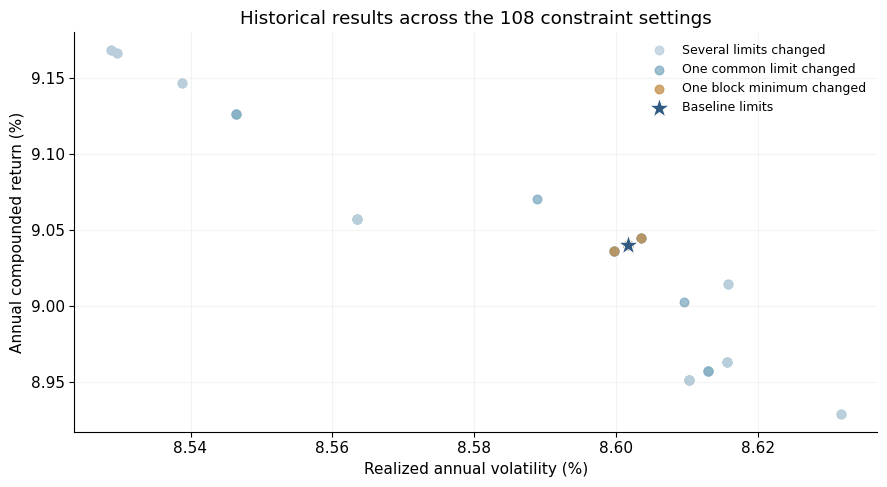

In [16]:
figure, axis = plt.subplots(figsize=(9, 5))
for kind, label, color in [("joint", "Several limits changed", "#b9cedb"),
                            ("one_limit", "One common limit changed", "#7caac1"),
                            ("individual_floor", "One block minimum changed", "#c28d48")]:
    scenarios = sensitivity.index[sensitivity["kind"] == kind]
    points = sensitivity_performance.loc[scenarios]
    axis.scatter(points["volatility"] * 100, points["cagr"] * 100, color=color,
                  s=38, alpha=0.75, label=label)
baseline_result = sensitivity_performance.loc["Baseline"]
axis.scatter(baseline_result["volatility"] * 100, baseline_result["cagr"] * 100,
             marker="*", s=230, color="#315b83", edgecolor="white", linewidth=0.7, zorder=5,
             label="Baseline limits")
axis.set(title="Historical results across the 108 constraint settings", xlabel="Realized annual volatility (%)",
         ylabel="Annual compounded return (%)")
axis.grid(alpha=0.15)
axis.legend(frameon=False, fontsize=9)
save_chart(figure, "constraint_backtest_comparison")

Every specification targets 8% volatility in the estimation window. Realized volatility over the historical comparison period can differ. The points are related allocations on the same return history, not independent performance observations.

## 4. What happens with an earlier estimation window?

We repeat the allocation exercise at two earlier starting points, using only the preceding 60 monthly returns for each fit. The resulting targets stay fixed during the following evaluation period, with monthly rebalancing.

| Test | Estimate weights using | Evaluate using |
|:--|:--|:--|
| First | November 2011–October 2016 | November 2016–September 2026 |
| Second | November 2016–October 2021 | November 2021–September 2026 |

The six selected ETFs are used in both tests. MVO tries an 8% volatility target, then 7.5% and 7% only if the optimizer cannot find a feasible solution. Equal weight and risk parity are not scaled to that target. The reported target applies only to MVO.

The fitting windows exclude their later evaluation returns. However, the ETF universe and rules were chosen after reviewing history, so these tests are not untouched holdouts. The two evaluation periods also overlap.

In [17]:
def historical_parity(covariance):
    count = len(covariance)
    scaled = covariance / np.mean(np.diag(covariance))
    budgets = np.ones(count) / count
    solution = minimize(lambda x: 0.5 * x @ scaled @ x - budgets @ np.log(x),
                        np.ones(count), jac=lambda x: scaled @ x - budgets / x,
                        bounds=[(1e-10, None)] * count, method="L-BFGS-B",
                        options={"ftol": 1e-15, "gtol": 1e-10, "maxiter": 3000})
    weights = solution.x / solution.x.sum()
    assert np.max(abs(risk_shares(weights, covariance) - budgets)) < 1e-7
    return weights

historical_assets = ["SPY", "EEMV", "DBC", "VGSH", "SCHD", "STIP"]
historical_results = []
historical_weights = []
for first_test_month in ["2016-11-30", "2021-11-30"]:
    start = pd.Timestamp(first_test_month)
    sample = returns.loc[returns.index < start, historical_assets].tail(60)
    assert len(sample) == 60 and sample.index[-1] < start
    trained_weights = None
    for target in [0.08, 0.075, 0.07]:
        try:
            trained_weights, diagnostics = optimize_weights(sample, POLICY, target=target)
            break
        except RuntimeError:
            continue
    if trained_weights is None:
        raise RuntimeError("No verified historical fit in the volatility band.")
    sample_covariance = sample.cov().to_numpy() * 12
    alternatives = {"Trained MVO": trained_weights,
                    "Equal weight": np.ones(6) / 6,
                    "Trained risk parity": historical_parity(sample_covariance)}
    for name, weights in alternatives.items():
        net = simulate_fixed_weights(weights, returns.loc[start:, historical_assets])["net_return"]
        row = performance_statistics(net).to_dict()
        row.update(test_start=first_test_month, portfolio=name, fit_first=str(sample.index[0].date()),
                   fit_last=str(sample.index[-1].date()), selected_mvo_volatility_target=target)
        historical_results.append(row)
        historical_weights.append({"test_start": first_test_month, "portfolio": name,
                                   **dict(zip(historical_assets, weights))})
historical_summary = pd.DataFrame(historical_results)
historical_summary.to_csv(STUDIES / "historical_fit_summary.csv", index=False)
pd.DataFrame(historical_weights).to_csv(STUDIES / "historical_fit_weights.csv", index=False)

historical_display = historical_summary[["test_start", "portfolio", "selected_mvo_volatility_target",
                                        "cagr", "volatility", "sharpe"]].copy()
historical_display.loc[historical_display["portfolio"] != "Trained MVO", "selected_mvo_volatility_target"] = np.nan
display(historical_display.rename(columns={"test_start": "Evaluation starts", "portfolio": "Portfolio",
    "selected_mvo_volatility_target": "MVO fit target", "cagr": "Annual return",
    "volatility": "Realized volatility", "sharpe": "Sharpe"})
    .style.format({"MVO fit target": "{:.1%}", "Annual return": "{:.2%}",
                   "Realized volatility": "{:.2%}", "Sharpe": "{:.3f}"}, na_rep="—"))

,Evaluation starts,Portfolio,MVO fit target,Annual return,Realized volatility,Sharpe
0,2016-11-30,Trained MVO,8.0%,10.68%,10.24%,0.807
1,2016-11-30,Equal weight,—,8.49%,8.30%,0.731
2,2016-11-30,Trained risk parity,—,2.96%,2.06%,0.241
3,2021-11-30,Trained MVO,8.0%,7.60%,7.18%,0.520
4,2021-11-30,Equal weight,—,7.67%,7.80%,0.493
5,2021-11-30,Trained risk parity,—,2.74%,2.47%,-0.458


### How the estimated MVO weights change

These are the exact allocations estimated at each earlier starting point. They are separate historical portfolios, not changes to the main target allocation.

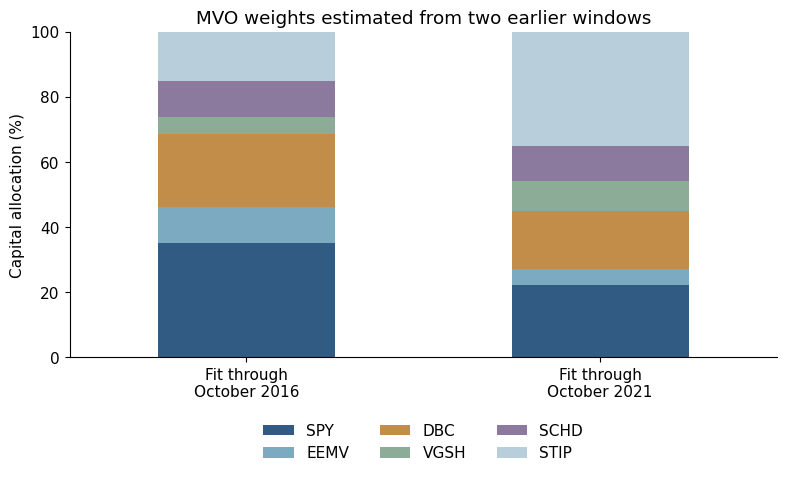

In [18]:
historical_weight_table = pd.DataFrame(historical_weights)
mvo_weights_by_window = historical_weight_table.loc[historical_weight_table["portfolio"] == "Trained MVO"]
mvo_weights_by_window = mvo_weights_by_window.set_index("test_start")[historical_assets]
mvo_weights_by_window.index = ["Fit through\nOctober 2016", "Fit through\nOctober 2021"]
figure, axis = plt.subplots(figsize=(8, 5))
(mvo_weights_by_window * 100).plot.bar(stacked=True, ax=axis, rot=0, width=0.5,
    color=[ASSET_COLORS[ticker] for ticker in historical_assets])
axis.set(title="MVO weights estimated from two earlier windows", ylabel="Capital allocation (%)",
         xlabel="", ylim=(0, 100))
axis.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16))
save_chart(figure, "historical_fit_allocations")

### Compare the strategies within each period

The shaded strip is the 7–9% volatility budget. It provides context for realized volatility; it is not a guarantee that a portfolio remains inside the band after estimation.

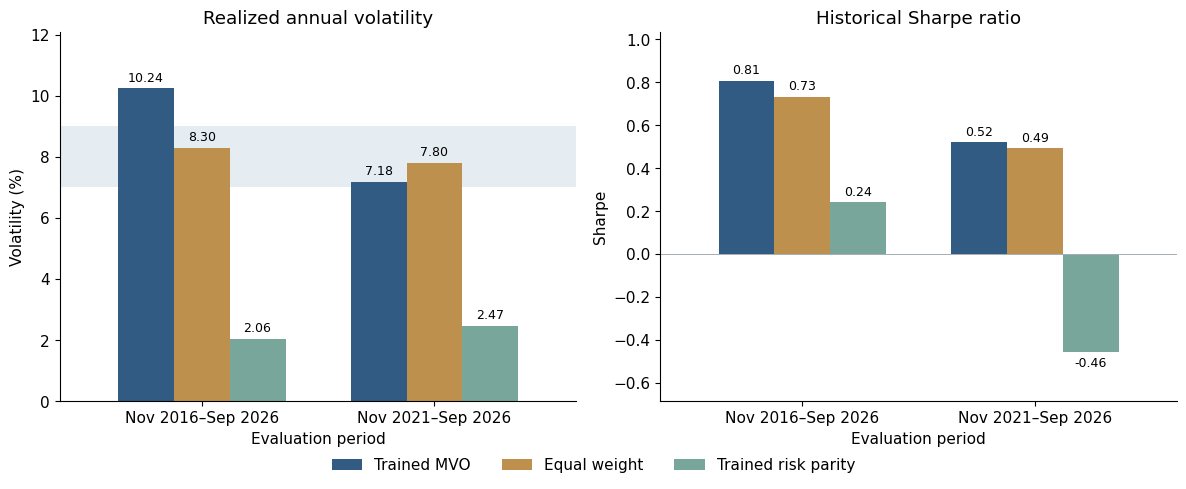

In [19]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.7))
strategy_order = list(STRATEGY_COLORS)
window_labels = ["Nov 2016–Sep 2026", "Nov 2021–Sep 2026"]
for axis, metric, title in [(axes[0], "volatility", "Realized annual volatility"),
                             (axes[1], "sharpe", "Historical Sharpe ratio")]:
    table = historical_summary.pivot(index="test_start", columns="portfolio", values=metric)[strategy_order]
    if metric == "volatility":
        table = table * 100
        axis.axhspan(7, 9, facecolor="#e5edf3", zorder=0)
    table.index = window_labels
    table.plot.bar(ax=axis, width=0.72, rot=0, color=[STRATEGY_COLORS[name] for name in strategy_order], legend=False)
    for container in axis.containers:
        axis.bar_label(container, fmt="%.2f", padding=3, fontsize=9)
    axis.set(title=title, xlabel="Evaluation period", ylabel="Volatility (%)" if metric == "volatility" else "Sharpe")
    axis.margins(y=0.18)
    axis.axhline(0, color="#a5adb5", lw=0.7)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.05))
save_chart(figure, "historical_fit_performance")

The estimation period changes the chosen weights and the subsequent results. An initial 8% volatility estimate does not guarantee 8% realized volatility. Differences between MVO and risk parity here also reflect their different risk levels.

## 5. How much do trading costs matter?

We keep the main notebook's rounded target weights fixed and repeat its monthly backtest at three cost assumptions: 0, 10 and 25 basis points per dollar traded. Initial investment is charged in each case. The 10-basis-point case is the main assumption.

For example, trading USD 1 million at 10 basis points costs USD 1,000. The same net-return formula from Section 3 is used in all cases.

In [20]:
main_weights = allocation["target_weight"].to_numpy()
cost_checks = pd.DataFrame({
    str(cost): performance_statistics(simulate_fixed_weights(main_weights, study_evaluation, cost)["net_return"])
    for cost in [0.0, 0.001, 0.0025]
}).T
cost_checks.index.name = "cost_per_dollar_traded"
cost_checks.to_csv(STUDIES / "trading_cost_sensitivity.csv")

cost_display = cost_checks[["cagr", "volatility", "sharpe"]].copy()
cost_display.index = ["0 bp", "10 bp — main assumption", "25 bp"]
display(cost_display.rename(columns={"cagr": "Annual return", "volatility": "Realized volatility", "sharpe": "Sharpe"})
        .style.format({"Annual return": "{:.2%}", "Realized volatility": "{:.2%}", "Sharpe": "{:.3f}"}))

,Annual return,Realized volatility,Sharpe
0 bp,9.08%,8.60%,0.772
10 bp — main assumption,9.04%,8.60%,0.768
25 bp,8.98%,8.60%,0.762


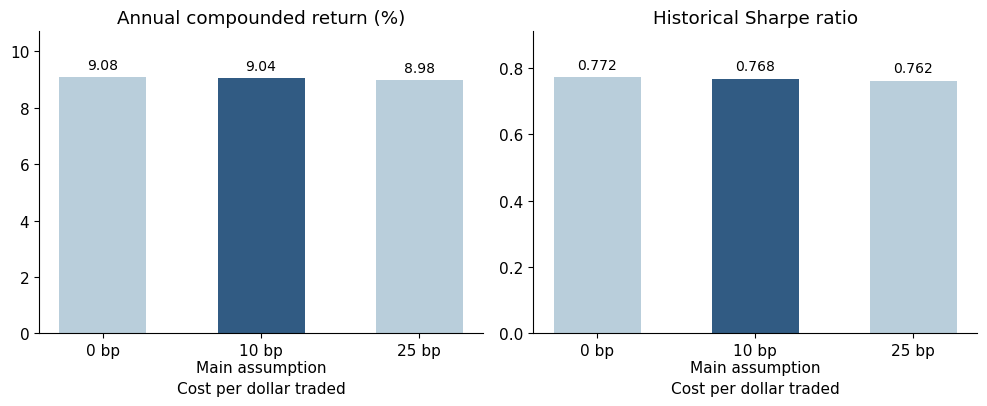

In [21]:
figure, axes = plt.subplots(1, 2, figsize=(10, 4.2))
cost_labels = ["0 bp", "10 bp\nMain assumption", "25 bp"]
for axis, column, title, scale in [(axes[0], "cagr", "Annual compounded return (%)", 100),
                                  (axes[1], "sharpe", "Historical Sharpe ratio", 1)]:
    bars = axis.bar(cost_labels, cost_checks[column] * scale,
                    color=["#b9cedb", "#315b83", "#b9cedb"], width=0.55)
    axis.bar_label(bars, fmt="%.3f" if column == "sharpe" else "%.2f", padding=4, fontsize=10)
    axis.set(title=title, xlabel="Cost per dollar traded")
    axis.set_ylim(0, cost_checks[column].max() * scale * 1.18)
save_chart(figure, "trading_cost_comparison")

## 6. How uncertain is the historical Sharpe ratio?

The reported Sharpe comes from one observed return history. To see how much it can vary, we use a block bootstrap:

1. Pair each net portfolio return with its month's risk-free proxy
2. Draw six-month blocks of these pairs, wrapping around the end of the sample
3. Join the blocks to make a sample with the original number of months
4. Calculate its annualized Sharpe and repeat 3,000 times

The middle 95% of the resulting estimates gives a conditional bootstrap interval. Blocks retain some of the dependence between neighbouring months.

**Interpretation:** this measures sampling uncertainty for the chosen strategy. It does not correct for choosing the ETFs, constraints or model after reviewing historical results, and it is not a forecast range for future Sharpe.

In [22]:
net = simulate_fixed_weights(main_weights, study_evaluation)["net_return"]
observations = net.to_numpy()
paired_risk_free = risk_free.reindex(net.index).to_numpy()
generator = np.random.default_rng(20261014)
block_length = 6
bootstrap_sharpes = []
for _ in range(3000):
    block_starts = generator.integers(0, len(net), size=(len(net) + block_length - 1) // block_length)
    indexes = np.concatenate([(start + np.arange(block_length)) % len(net) for start in block_starts])[:len(net)]
    sampled_returns = observations[indexes]
    sampled_risk_free = paired_risk_free[indexes]
    bootstrap_sharpes.append((sampled_returns - sampled_risk_free).mean()
                             / sampled_returns.std(ddof=1) * np.sqrt(12))
interval = pd.Series({"lower_2.5pct": np.quantile(bootstrap_sharpes, 0.025),
                      "upper_97.5pct": np.quantile(bootstrap_sharpes, 0.975)}, name="conditional_sharpe_interval")
interval.to_csv(STUDIES / "sharpe_bootstrap_interval.csv")

observed_sharpe = performance_statistics(net)["sharpe"]
display(pd.Series({"Historical Sharpe": observed_sharpe,
                   "Bootstrap lower bound (2.5%)": interval["lower_2.5pct"],
                   "Bootstrap upper bound (97.5%)": interval["upper_97.5pct"]}, name="Estimate")
        .to_frame().style.format("{:.3f}"))

,Estimate
Historical Sharpe,0.768
Bootstrap lower bound (2.5%),0.189
Bootstrap upper bound (97.5%),1.566


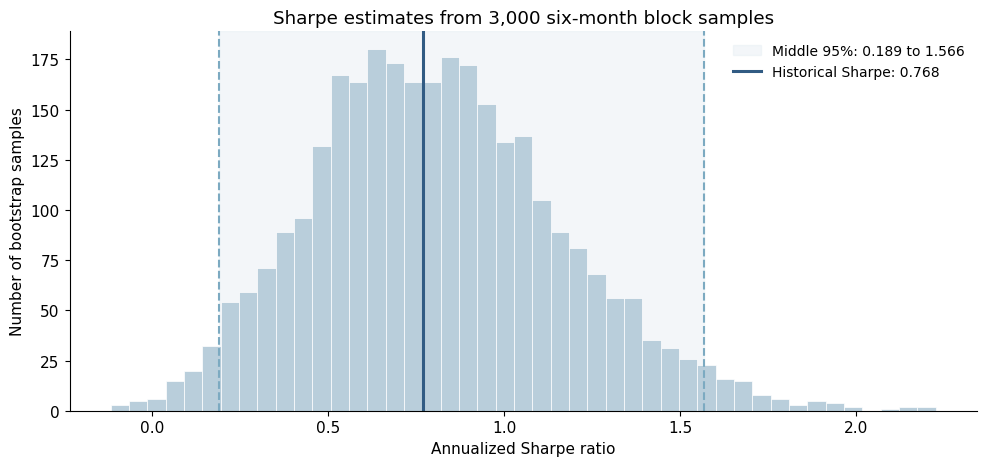

In [23]:
lower, upper = interval["lower_2.5pct"], interval["upper_97.5pct"]
figure, axis = plt.subplots(figsize=(10, 4.8))
axis.hist(bootstrap_sharpes, bins=45, color="#b9cedb", edgecolor="white", linewidth=0.5)
axis.axvspan(lower, upper, color="#e5edf3", alpha=0.45, zorder=0,
               label=f"Middle 95%: {lower:.3f} to {upper:.3f}")
axis.axvline(lower, color="#7caac1", linestyle="--", lw=1.5)
axis.axvline(upper, color="#7caac1", linestyle="--", lw=1.5)
axis.axvline(observed_sharpe, color="#315b83", lw=2.2,
               label=f"Historical Sharpe: {observed_sharpe:.3f}")
axis.set(title="Sharpe estimates from 3,000 six-month block samples",
         xlabel="Annualized Sharpe ratio", ylabel="Number of bootstrap samples")
axis.legend(frameon=False, fontsize=10)
save_chart(figure, "sharpe_uncertainty")

## Appendix. Backtest accounting

This optional calculation reproduces the main comparison using dollar holdings. At each month-start, it calculates trades and fees, invests the remaining capital at the target weights and applies that month's ETF returns. The resulting monthly returns should agree with the return formula in Section 3.

Risk shares are also calculated directly from each ETF's covariance with portfolio returns

$$RC_i=\frac{w_i\sigma_{ip}}{\sigma_p^2}$$

Here $\sigma_{ip}$ is the covariance between the ETF return and the portfolio return, and $\sigma_p^2$ is the portfolio return variance.

In [24]:
held_assets = [ticker for ticker in ["SPY", "EEMV", "DBC", "VGSH", "SCHD", "STIP"]
               if allocation.loc[ticker, "target_weight"] > 1e-8]
held_covariance = annual_covariance.loc[held_assets, held_assets].to_numpy()
benchmark_weights = {
    "Constrained MVO": allocation.loc[held_assets, "target_weight"].to_numpy(),
    "Equal weight": np.ones(len(held_assets)) / len(held_assets),
    "Risk parity": historical_parity(held_covariance),
}
evaluation = returns.loc[BACKTEST_START:, held_assets]
backtest_returns = pd.DataFrame({name: simulate_fixed_weights(weights, evaluation)["net_return"]
                                 for name, weights in benchmark_weights.items()})

In [25]:
accounting_checks = []
for name, weights in benchmark_weights.items():
    holdings = np.zeros(len(weights))
    nav = float(CAPITAL)
    independent_returns = []
    for _, observations in evaluation.iterrows():
        initial_nav = nav
        dollars_traded = np.abs(initial_nav * weights - holdings).sum()
        fee = TRADING_COST * dollars_traded
        holdings = (initial_nav - fee) * weights * (1 + observations.to_numpy())
        nav = float(holdings.sum())
        independent_returns.append(nav / initial_nav - 1)
    difference = np.max(abs(np.array(independent_returns) - backtest_returns[name].to_numpy()))
    assert difference < 1e-12
    accounting_checks.append([name, len(independent_returns), difference])
display(pd.DataFrame(accounting_checks, columns=["Portfolio", "Months checked", "Largest return difference"])
        .set_index("Portfolio").style.format({"Months checked": "{:.0f}", "Largest return difference": "{:.2e}"}))

direct_portfolio_returns = training.to_numpy() @ target_weights
direct_variance = np.var(direct_portfolio_returns, ddof=1) * 12
direct_shares = np.array([
    target_weights[i] * np.cov(training.iloc[:, i], direct_portfolio_returns, ddof=1)[0, 1] * 12 / direct_variance
    for i in range(len(ASSETS))
])
assert np.max(abs(direct_shares - allocation["risk_share"].to_numpy())) < 1e-10
assert policy_margins(target_weights, covariance, ASSETS, POLICY).min() >= -1e-10
assert abs(target_weights.sum() - 1) < 1e-12

,Months checked,Largest return difference
Portfolio,,
Constrained MVO,119,4.44e-16
Equal weight,119,4.44e-16
Risk parity,119,4.44e-16


## Saved results

All supporting tables and figures are in `studies/`. The figures above are saved as both PNG and PDF.

| Files | Contents |
|:--|:--|
| `constraint_sensitivity.csv` | Exact weights and risk shares for the 108 constraint settings |
| `constraint_backtest_context.csv` | Retrospective performance under those settings |
| `source_comparison.csv` | Bloomberg–Yahoo monthly return differences |
| `historical_fit_weights.csv` and `historical_fit_summary.csv` | Earlier estimated portfolios and subsequent performance |
| `trading_cost_sensitivity.csv` | Results at the three cost assumptions |
| `sharpe_bootstrap_interval.csv` | Conditional Sharpe interval |

`research_variations.csv` is a retained log of earlier allocation experiments. It is separate from the calculations in this notebook. Some entries describe the same portfolios in different comparisons, so their counts cannot be summed as a number of unique tests. Its evidence references use the earlier research layout.